In [1]:
# Cell 0: Imports and settings
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import pycwt
from datetime import datetime, timedelta
import os

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'

USE_SUNDOWNER = False

IOP_start = datetime(2022, 5, 12, 10, 0, 0)
IOP_end   = datetime(2022, 5, 13, 8, 0, 0)

if USE_SUNDOWNER:
    ANALYSIS_START = datetime(2022, 5, 12, 20, 0, 0)
    ANALYSIS_END   = datetime(2022, 5, 13,  6, 0, 0)
    PERIOD_LABEL   = 'Sundowner period (May 12 20:00 - May 13 06:00 PDT)'
    FILE_TAG       = 'sundowner'
else:
    ANALYSIS_START = IOP_start
    ANALYSIS_END   = IOP_end
    PERIOD_LABEL   = 'IOP10 full period (May 12 10:00 - May 13 08:00 PDT)'
    FILE_TAG       = 'IOP10'

TARGET_HEIGHTS = [750, 500, 250]   # [m] heights for scalograms
BAND_MIN       = 45                 # [min] band for intermittency panel
BAND_MAX       = 90                # [min]
RAW_W_HEIGHT   = 500               # [m] height shown in raw-w panel

UWOW_MAT  = r'/home/voyager-sbarc/duine/sundowners/swex2022/data/uwow/prelim/IOP10_stationary/stare/UWOW_stare_IOP10.mat'
OUTDIR    = r'/home/voyager-sbarc/duine/sundowners/swex2022/analysis/analysis_IOP10/spectral_stares'
SNR_THRESH = -28.5   # [dB]

def dn2dt(dn):
    return datetime.fromordinal(int(dn) - 366) + timedelta(days=dn % 1)

def dt2dn(dt):
    return dt.toordinal() + 366 + (dt.hour*3600 + dt.minute*60 + dt.second) / 86400

dn_start = dt2dn(ANALYSIS_START)
dn_end   = dt2dn(ANALYSIS_END)

print(f'Analysis window: {PERIOD_LABEL}')
print(f'Target heights: {TARGET_HEIGHTS} m')

Analysis window: IOP10 full period (May 12 10:00 - May 13 08:00 PDT)
Target heights: [750, 500, 250] m


In [2]:
# Cell 1: Load UWOW data
print('Loading UWOW ...')
mat      = sio.loadmat(UWOW_MAT)
t_uwow   = mat['uwowStareTnumPDT'].ravel()
W_uwow   = mat['uwowStareVertW'].astype(float)
snr_uwow = mat['uwowStareSNR']
elev     = mat['uwowElevation'].ravel()

keep     = (t_uwow >= dn_start) & (t_uwow <= dn_end)
t_uwow   = t_uwow[keep]
W_uwow   = W_uwow[:, keep]
snr_uwow = snr_uwow[:, keep]

W_uwow[snr_uwow < SNR_THRESH] = np.nan
W_uwow = W_uwow[2:, :]   # drop lowest 2 gates (ground clutter)
elev   = elev[2:]

print(f'UWOW: {len(t_uwow)} time steps, {W_uwow.shape[0]} gates')
print(f'Height range: {elev[0]:.0f} – {elev[-1]:.0f} m')
print(f'Data coverage: {len(t_uwow)/86400*100:.1f}% of 24 h')

Loading UWOW ...
UWOW: 67961 time steps, 198 gates
Height range: 75 – 5985 m
Data coverage: 78.7% of 24 h


In [3]:
# Cell 2: CWT helpers and compute for all target heights
# Runtime: ~1-2 min per height

t_grid = np.arange(dn_start, dn_end, 1/86400)   # 1-Hz regular grid
t_dt   = np.array([dn2dt(t) for t in t_grid])
t_num  = mdates.date2num(t_dt)

dt_cwt = 1.0
dj     = 0.125
s0     = 2 * dt_cwt
J      = int(np.log2(len(t_grid) * dt_cwt / s0) / dj)
mother = pycwt.Morlet(6)

def make_cont(g):
    w  = W_uwow[g, :].astype(float)
    ok = np.isfinite(w)
    wc = np.interp(t_grid, t_uwow[ok], w[ok], left=np.nan, right=np.nan)
    wc = np.where(np.isfinite(wc), wc, 0.0)
    wc -= wc.mean()
    return wc

def run_cwt(g):
    w_cont                              = make_cont(g)
    wave, scales, freqs_wav, coi, _, _ = pycwt.cwt(w_cont, dt_cwt, dj, s0, J, mother)
    power                               = np.abs(wave)**2
    period_min                          = 1.0 / freqs_wav / 60
    alpha, _, _                         = pycwt.ar1(w_cont)
    signif, _                           = pycwt.significance(w_cont.std()**2, dt_cwt, scales, 0,
                                                               alpha, significance_level=0.95,
                                                               wavelet=mother)
    sig95 = power / signif[:, np.newaxis]
    return power, period_min, coi / 60, sig95, signif

results = {}
for h_tgt in TARGET_HEIGHTS:
    g = np.argmin(np.abs(elev - h_tgt))
    h = elev[g]
    print(f'CWT at {h:.0f} m (gate {g}) ...')
    power, period_min, coi_min, sig95, signif = run_cwt(g)
    results[h_tgt] = dict(g=g, h=h, power=power, period_min=period_min,
                          coi_min=coi_min, sig95=sig95, signif=signif)

print('Done.')

CWT at 765 m (gate 23) ...
CWT at 525 m (gate 15) ...
CWT at 255 m (gate 6) ...
Done.


Saved wavelet_multiH_UWOW_750_500_250m_band45-90min_IOP10.png
Saved wavelet_multiH_UWOW_750_500_250m_band45-90min_IOP10.pdf


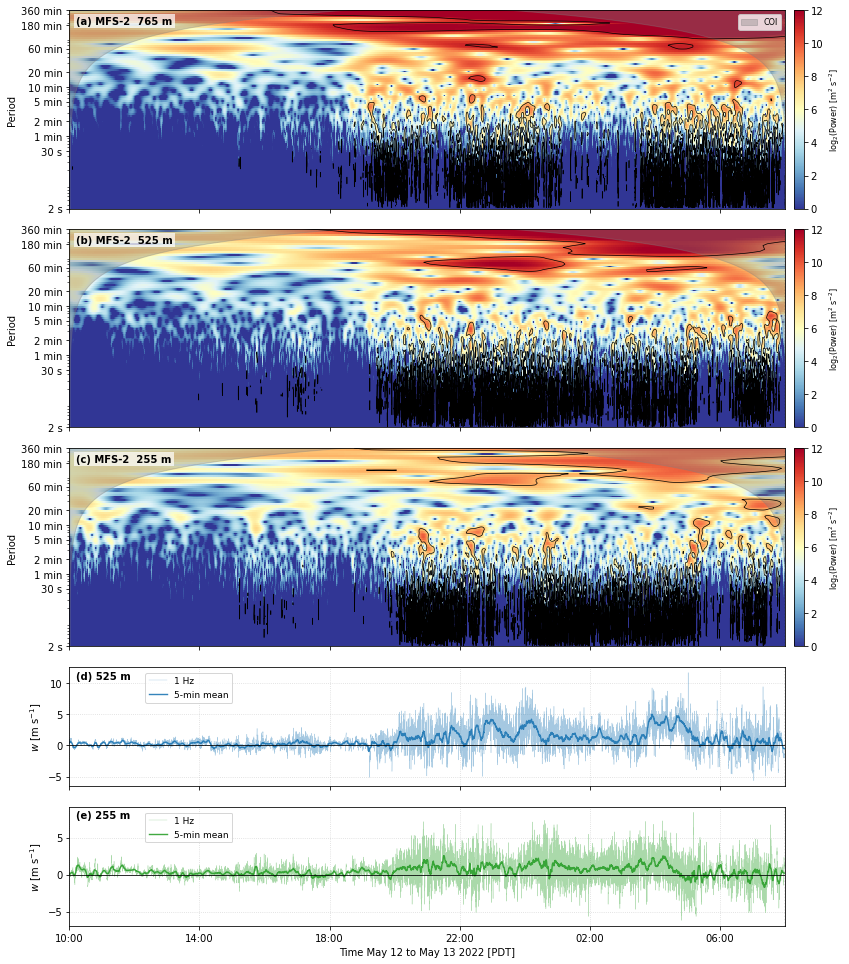

In [8]:
# Cell 3: 5-panel figure
# a-c  wavelet scalograms at TARGET_HEIGHTS
# d    1 Hz + 5-min mean at TARGET_HEIGHTS[1] (500 m)
# e    1 Hz + 5-min mean at TARGET_HEIGHTS[2] (250 m)

colors_band  = ['tab:blue', 'tab:orange', 'tab:green']
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)']
t_uwow_end   = datetime(2022, 5, 13, 8, 0, 0)

n = len(TARGET_HEIGHTS)
height_ratios = [2.5] * n + [1.5, 1.5]
fig, axes = plt.subplots(n + 2, 1,
                         figsize=(13, 2.5 * n + 6),
                         gridspec_kw={'height_ratios': height_ratios},
                         sharex=True)

ax_scalo = axes[:n]
ax_w1    = axes[n]       # panel d: 500 m
ax_w2    = axes[n + 1]   # panel e: 250 m

# --- Panels a-c: scalograms ---
for ax, h_tgt, color, plabel in zip(ax_scalo, TARGET_HEIGHTS, colors_band, panel_labels):
    r          = results[h_tgt]
    period_min = r['period_min']
    pm, tm     = np.meshgrid(period_min, t_num, indexing='ij')
    pcm = ax.pcolormesh(tm, pm, np.log2(np.maximum(r['power'], 1e-10)),
                        shading='nearest', cmap='RdYlBu_r', vmin=0, vmax=12, rasterized=True)
    ax.xaxis_date()
    ax.contour(t_dt, period_min, r['sig95'], levels=[1.0], colors='k', linewidths=0.7)
    ax.fill_between(t_dt, r['coi_min'], period_min[-1], color='grey', alpha=0.35, label='COI')
    ax.axhspan(BAND_MIN, BAND_MAX, color='gold', alpha=0.2, zorder=0)
    ax.axvline(mdates.date2num(t_uwow_end), color='k', ls=':', lw=1.2)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_yticks([2/60, 0.5, 1, 2, 5, 10, 20, 60, 180, 360])
    ax.set_yticklabels(['2 s', '30 s', '1 min', '2 min', '5 min', '10 min', '20 min', '60 min', '180 min', '360 min'])
    ax.set_ylim([2/60, 360])
    ax.set_ylabel('Period')
    cb = fig.colorbar(pcm, ax=ax, pad=0.01, aspect=20)
    cb.set_label(r'log$_2$(Power) [m$^2$ s$^{-2}$]', fontsize=8)
    ax.text(0.01, 0.97, f'{plabel} MFS-2  {r["h"]:.0f} m',
            transform=ax.transAxes, va='top', ha='left', fontsize=10, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

ax_scalo[0].legend(loc='upper right', fontsize=8)

# --- Helper: plot w panel ---
def plot_w_panel(ax, h_tgt, color, plabel):
    g         = results[h_tgt]['g']
    h         = results[h_tgt]['h']
    idx_all   = np.arange(W_uwow.shape[1])
    t_uwow_dt = np.array([dn2dt(t) for t in t_uwow])
    t_uwow_n  = mdates.date2num(t_uwow_dt)
    w_raw     = W_uwow[g, :].astype(float)
    valid     = np.isfinite(w_raw)
    w_interp  = np.interp(idx_all, idx_all[valid], w_raw[valid])
    w_smooth  = np.convolve(w_interp, np.ones(300) / 300, mode='same')   # 5 min
    w_smooth[~valid] = np.nan
    ax.plot(t_uwow_n, w_raw,    color=color, lw=0.4, alpha=0.4, label='1 Hz')
    ax.plot(t_uwow_n, w_smooth, color=color, lw=1.4, alpha=0.9, label='5-min mean')
    ax.axhline(0, color='k', lw=0.8)
    ax.axvline(t_uwow_end, color='k', ls=':', lw=1.2)
    ax.set_ylabel(r'$w$ [m s$^{-1}$]')
    ax.grid(True, ls=':', alpha=0.5)
    ax.legend(loc='upper left', bbox_to_anchor=(0.10, 0.99), fontsize=9)
    ax.text(0.01, 0.97, f'{plabel} {h:.0f} m', transform=ax.transAxes,
            va='top', ha='left', fontsize=10, fontweight='bold')

plot_w_panel(ax_w1, TARGET_HEIGHTS[1], colors_band[0], '(d)')
plot_w_panel(ax_w2, TARGET_HEIGHTS[2], colors_band[2], '(e)')

ax_w2.set_xlabel('Time May 12 to May 13 2022 [PDT]')
ax_w2.xaxis_date()
ax_w2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_w2.xaxis.set_major_locator(mdates.HourLocator(byhour=[2, 6, 10, 14, 18, 22]))

fig.tight_layout()

# Align right edges of all panels to the scalogram width (narrowed by colorbars)
pos_ref = ax_scalo[-1].get_position()
for ax in list(ax_scalo) + [ax_w1, ax_w2]:
    p = ax.get_position()
    ax.set_position([pos_ref.x0, p.y0, pos_ref.width, p.height])

for ext, kw in [('png', {'dpi': 150}), ('pdf', {'dpi': 300})]:
    fname = (f'wavelet_multiH_UWOW_'
             f'{"_".join(str(h) for h in TARGET_HEIGHTS)}m_'
             f'band{BAND_MIN}-{BAND_MAX}min_{FILE_TAG}.{ext}')
    fig.savefig(os.path.join(OUTDIR, fname), bbox_inches='tight', **kw)
    print(f'Saved {fname}')

plt.show()